# Collinearity of $\hat u$ and $\widehat{u^2}$ for travelling waves

For each wavenumber $\xi\neq0$ the LSM solves $A_\xi x=b$ with $x=(l(\xi),n(\xi))^T$ and rows

$$
A_\xi[s,:]=-i\xi\,\big(\hat u^{(s)}(\xi),\ \widehat{u^2}^{(s)}(\xi)\big),\qquad b_s=\hat u^{(s)}_t(\xi),
$$

where $s$ runs over (wave, frame). For a travelling wave $u=\phi(x-ct)$ both entries get the same phase $e^{-i\xi ct}$,
so all rows are proportional and $\operatorname{rank}A_\xi=1$. This notebook checks that claim numerically and shows what it means for the recovery.

1. Dealiased product of two spectra (reworked from `product_hat`)
2. Data: two Newton travelling waves, evolved with the PDE solver and by exact translation
3. The ratio $\widehat{u^2}/\hat u$ is constant in time for a travelling wave
4. Geometry: one wave gives a line in the $(l,n)$-plane, two waves give a point
5. Singular values: travelling vs. non-travelling data
6. The determinant identity $D_\xi=\hat\phi_1\hat\phi_2\,(c_2-c_1)/n$
7. Conditioning against speed difference

In [2]:
import sys
from pathlib import Path

root = Path.cwd().parent
sys.path.insert(0,str(root))

In [ ]:
import numpy as np
import numpy.fft as nf
import matplotlib.pyplot as plt

from camera.help import *
from camera.camera_file import Camera
from camera.spectralCamera import KdVNewton
from camera.pdeCamera import KdV

plt.rcParams.update({"figure.figsize": (6.5, 4), "axes.grid": True})

## 1. Dealiased product on the full spectrum

`product_hat` in `spectralCamera` works on the half spectrum (`rfft` layout) and is tied to the solver object.
For data analysis we need the same operation on **full `fft` spectra**, along the last axis, so that a whole `(time, k)` array is handled at once.

Convention: $\hat h_k$ are Fourier *coefficients* (`fft(h)/N`). The spectra are zero-padded to $3N/2$,
multiplied in physical space, transformed back, and truncated to $|k|\le N/2-1$ (the Nyquist mode is dropped, as in the solver).

In [4]:
def product_hat_full(a_hat, b_hat):
    '''Coefficients of a*b with the 3/2 rule. Inputs/outputs: fft-ordered coefficients (fft(.)/N), last axis = k.'''
    N = a_hat.shape[-1]
    half, Np = N // 2, 3 * N // 2

    def to_fine(h):
        out = np.zeros(h.shape[:-1] + (Np,), dtype=complex)
        out[..., :half]       = h[..., :half]
        out[..., -(half-1):]  = h[..., -(half-1):]      # Nyquist mode dropped
        return nf.ifft(Np * out, axis=-1)               # physical values on the fine grid

    p = nf.fft(to_fine(a_hat) * to_fine(b_hat), axis=-1) / Np
    out = np.zeros(a_hat.shape, dtype=complex)
    out[..., :half]       = p[..., :half]
    out[..., -(half-1):]  = p[..., -(half-1):]
    return out

def spectra(u):
    '''u: (frames, N) physical data -> (u_hat, q_hat) with q_hat = coefficients of u^2 (dealiased).'''
    u_hat = nf.fft(u, axis=-1) / u.shape[-1]
    return u_hat, product_hat_full(u_hat, u_hat)

Check against the solver's own `product_hat` (should agree to machine precision on modes $0,\dots,M-1$).

In [5]:
L, N, dt = 2*np.pi, 2**6, 1e-3
cam = Camera(L, N, dt)

def make_wave(amp):
    w = KdVNewton(P=L, target_amp=amp, mean=0.0, camera=cam)
    w.solve_w_continuation(n_steps=20)
    return w

w1, w2 = make_wave(0.10), make_wave(0.40)     # crest elevations above the mean
print(f"c1 = {w1.c:.6f},  c2 = {w2.c:.6f},  c2-c1 = {w2.c-w1.c:.6f}")

# validation of product_hat_full
phi = nf.fft(w2.get_physical(w2.phi_hat)) / N
q_full = product_hat_full(phi, phi)
q_ref  = w2.product_hat(w2.phi_hat, w2.phi_hat)
M = w2.M
print("max |difference| on modes 0..M-1:", np.max(np.abs(q_full[:M] - q_ref[:M])))

c1 = 0.835605,  c2 = 0.861814,  c2-c1 = 0.026209
max |difference| on modes 0..M-1: 7.286753003977687e-18


## 2. Data

Both waves are Newton solutions on the camera window ($P=L$, so no tiling is needed). Each is then evolved in two ways:

* **PDE:** the split-step solver `KdV` (includes time-stepping error),
* **exact:** pure translation, $\hat u(k,t)=\hat u(k,0)e^{-ikct}$ (a travelling wave by construction).

In [6]:
T, save_every = 10.0, 20
dt_frame = dt * save_every

def evolve_pde(u0):
    pde = KdV(camera=cam, T=T, u0=u0, save_every=save_every)
    t, u = pde.splitStep()
    return t, u

def evolve_exact(w, t):
    u_hat0 = nf.fft(w.get_physical(w.phi_hat))
    return nf.ifft(u_hat0[None, :] * np.exp(-1j * cam.k[None, :] * w.c * t[:, None]), axis=1).real

u0_1, u0_2 = (w.get_physical(w.phi_hat) for w in (w1, w2))
t, U1 = evolve_pde(u0_1)
_, U2 = evolve_pde(u0_2)
E1, E2 = evolve_exact(w1, t), evolve_exact(w2, t)
Usum = evolve_pde(u0_1 + u0_2)[1]            # NOT a travelling wave

print("frames:", len(t), " frame spacing:", dt_frame)

# does the PDE wave travel at the Newton speed?  phase of mode 1 is -k c t
ph = np.unwrap(np.angle(nf.fft(U2, axis=1)[:, 1]))
print("c from PDE phase:", -np.polyfit(t, ph, 1)[0] / cam.k[1], "  Newton c:", w2.c)

frames: 501  frame spacing: 0.02
c from PDE phase: 0.8618136060884187   Newton c: 0.8618136096946277


## 3. The ratio $r(\xi,t)=\widehat{u^2}/\hat u$ is constant in time

If the rows of $A_\xi$ are proportional, then $r(\xi,t)$ does not depend on $t$. For the exact translation this holds to rounding error;
for the PDE data the deviation measures the time-stepping error. For the sum of two waves it is a genuine change.

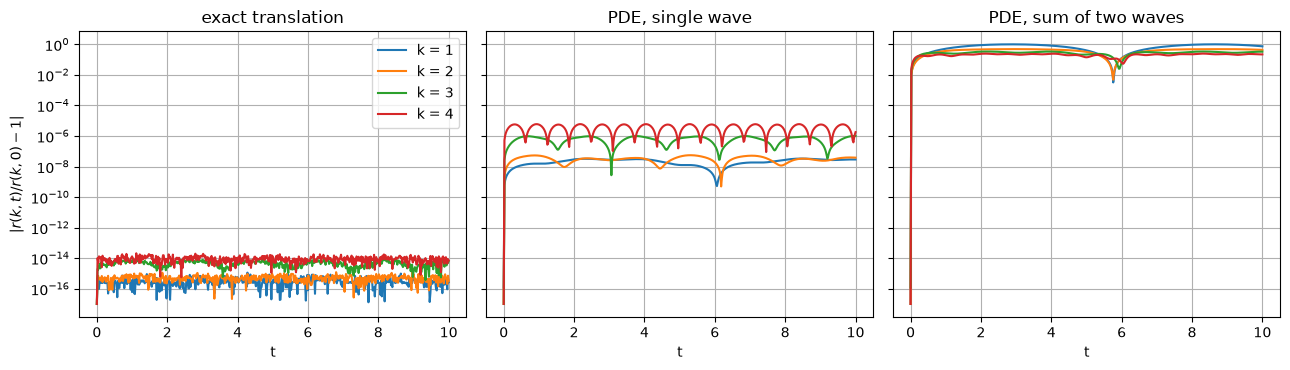

In [7]:
def ratio_drift(u, ks):
    u_hat, q_hat = spectra(u)
    r = q_hat[:, ks] / u_hat[:, ks]
    return np.abs(r / r[0] - 1)

ks = [1, 2, 3, 4]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for a, (name, data) in zip(ax, [("exact translation", E2), ("PDE, single wave", U2), ("PDE, sum of two waves", Usum)]):
    d = ratio_drift(data, ks)
    for j, k in enumerate(ks):
        a.semilogy(t, d[:, j] + 1e-17, label=f"k = {k}")
    a.set_title(name); a.set_xlabel("t")
ax[0].set_ylabel(r"$|r(k,t)/r(k,0)-1|$"); ax[0].legend()
plt.tight_layout(); plt.show()

## 4. Geometry in the $(l,n)$-plane

For a travelling wave every frame gives the same equation, $l\,\hat\phi+n\,\hat q=c\,\hat\phi$, i.e. the line $l+r\,n=c$ with $r=\hat q/\hat\phi$.
A rank-1 least-squares solution (`pinv` that drops the vanishing singular value) is the point on that line **closest to the origin**, $c\,(1,r)/(1+r^2)$, which is not the true symbol.
Note that noise-free PDE data are only *almost* rank 1 (time-stepping error), so a full `pinv` can still use the tiny second singular value and succeed; with measurement noise that stops working. Both cases are shown.
Two waves with different speeds give two non-parallel lines that meet at $(l(\xi),n(\xi))$.

The cell below solves the regression at one mode with the fourth-order time derivative and compares.

single wave, sigma2/sigma1 = 1.53e-08
mode k = 2
true                          : l = 0.33333, n = 0.50000
single wave, truncated pinv   : l = 0.40706, n = 0.43025
single wave, full pinv, clean : l = 0.33333, n = 0.50000
single wave, noise 1e-7       : l = -0.23799, n = 1.04053
two waves,   noise 1e-7       : l = 0.33333, n = 0.50000


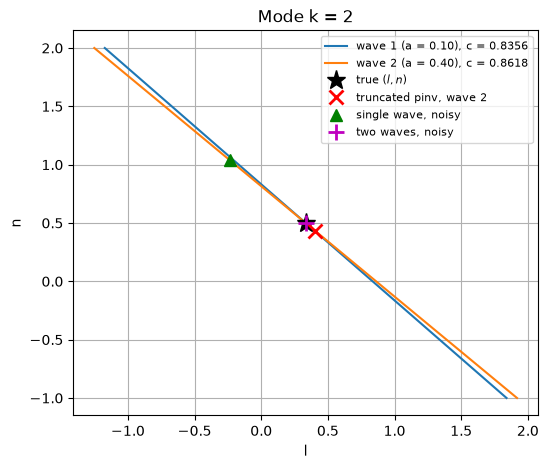

closest-point formula: [0.40706008 0.43024645]   truncated pinv: [0.40706006 0.43024643]


In [8]:
def ddt(u, dt):
    '''Fourth order stencil for the time derivative (output frames 2 .. n-3).'''
    return (-u[4:] + 8*(u[3:-1] - u[1:-3]) + u[:-4]) / (12*dt)

def build_system(waves, k_idx, dt_frame):
    '''waves: list of (frames, N) physical arrays. Returns A (S,2) and b (S,) for mode k_idx.'''
    k = cam.k[k_idx]
    A_rows, b_rows = [], []
    for u in waves:
        u_hat, q_hat = spectra(u)
        A_rows.append(-1j * k * np.stack([u_hat[2:-2, k_idx], q_hat[2:-2, k_idx]], axis=1))
        b_rows.append(ddt(u_hat[:, k_idx], dt_frame))
    return np.vstack(A_rows), np.concatenate(b_rows)

kk = 2
l_true, n_true = kdVDispersion(cam.k[kk]), 0.5

A2, b2 = build_system([U2], kk, dt_frame)
sv2 = np.linalg.svd(A2, compute_uv=False)
print(f"single wave, sigma2/sigma1 = {sv2[1]/sv2[0]:.2e}")

x1_trunc = np.linalg.pinv(A2, rcond=1e-6) @ b2          # treats the system as rank 1
x1_full  = np.linalg.pinv(A2) @ b2                       # keeps the tiny second singular value
rng = np.random.default_rng(0)
U2n = U2 + 1e-7 * rng.standard_normal(U2.shape)          # small measurement noise
U1n = U1 + 1e-7 * rng.standard_normal(U1.shape)
A2n, b2n = build_system([U2n], kk, dt_frame)
x1_noisy = np.linalg.pinv(A2n) @ b2n
x12      = np.linalg.lstsq(*build_system([U1n, U2n], kk, dt_frame), rcond=None)[0]

print(f"mode k = {kk}")
print(f"true                          : l = {l_true:.5f}, n = {n_true:.5f}")
print(f"single wave, truncated pinv   : l = {x1_trunc[0].real:.5f}, n = {x1_trunc[1].real:.5f}")
print(f"single wave, full pinv, clean : l = {x1_full[0].real:.5f}, n = {x1_full[1].real:.5f}")
print(f"single wave, noise 1e-7       : l = {x1_noisy[0].real:.5f}, n = {x1_noisy[1].real:.5f}")
print(f"two waves,   noise 1e-7       : l = {x12[0].real:.5f}, n = {x12[1].real:.5f}")

# lines l + r n = c for each wave
def line_params(u, w, k_idx):
    u_hat, q_hat = spectra(u[:1])
    return (q_hat[0, k_idx] / u_hat[0, k_idx]).real, w.c

r1, c1 = line_params(U1, w1, kk)
r2, c2 = line_params(U2, w2, kk)

nn = np.linspace(-1, 2, 200)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(c1 - r1*nn, nn, label=f"wave 1 (a = 0.10), c = {c1:.4f}")
ax.plot(c2 - r2*nn, nn, label=f"wave 2 (a = 0.40), c = {c2:.4f}")
ax.plot(l_true, n_true, "k*", ms=14, label="true $(l,n)$")
ax.plot(*(c2 * np.array([1, r2]) / (1 + r2**2)), "rx", ms=10, mew=2, label="truncated pinv, wave 2")
ax.plot(x1_noisy[0].real, x1_noisy[1].real, "g^", ms=8, label="single wave, noisy")
ax.plot(x12[0].real, x12[1].real, "m+", ms=12, mew=2, label="two waves, noisy")
ax.set_xlabel("l"); ax.set_ylabel("n"); ax.set_title(f"Mode k = {kk}"); ax.legend(fontsize=8)
plt.show()
print("closest-point formula:", c2 * np.array([1, r2]) / (1 + r2**2), "  truncated pinv:", x1_trunc.real)

## 5. Singular values of the normalised system

With the columns of $A_\xi$ scaled to unit norm (as in `lsmCamera`), $\sigma_2/\sigma_1$ measures how far the two columns are from collinear.
Expect $\approx10^{-16}$ for exact translation, a small floor for single PDE waves (time-stepping error), a larger value for the non-travelling sum, and $O(1)$ for two travelling waves of different speed.

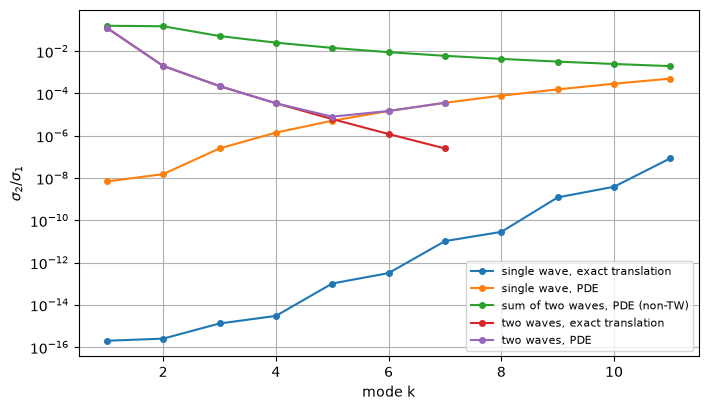

In [9]:
def sv_ratio(waves, ks):
    out = []
    for k_idx in ks:
        A = np.vstack([ -1j*cam.k[k_idx]*np.stack([spectra(u)[0][:, k_idx], spectra(u)[1][:, k_idx]], axis=1) for u in waves])
        A = A / np.linalg.norm(A, axis=0, keepdims=True)
        s = np.linalg.svd(A, compute_uv=False)
        out.append(s[1] / s[0])
    return np.array(out)

# only modes that are populated in every wave used
def populated(waves, tol=1e-10):
    m = np.ones(N, dtype=bool)
    for u in waves:
        a = np.abs(spectra(u[:1])[0][0])
        m &= a > tol * a[1:N//2].max()
    return np.where(m[1:N//2])[0] + 1

cases = {
    "single wave, exact translation": [E2],
    "single wave, PDE":               [U2],
    "sum of two waves, PDE (non-TW)": [Usum],
    "two waves, exact translation":   [E1, E2],
    "two waves, PDE":                 [U1, U2],
}
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, wv in cases.items():
    ks_ = populated(wv)
    ax.semilogy(ks_, sv_ratio(wv, ks_) + 1e-18, "o-", ms=4, label=name)
ax.set_xlabel("mode k"); ax.set_ylabel(r"$\sigma_2/\sigma_1$"); ax.legend(fontsize=8)
plt.show()

## 6. The determinant identity

With $r_j=\hat q_j/\hat\phi_j$ and the true symbols satisfying $c_j=l+n\,r_j$, the $2\times2$ determinant is
$D_\xi=\hat\phi_1\hat q_2-\hat\phi_2\hat q_1=\hat\phi_1\hat\phi_2\,(c_2-c_1)/n$.
Here $\hat q$ is the dealiased product, which is exactly what the Newton residual uses, so the identity holds to the Newton tolerance.

In [10]:
phi1 = nf.fft(u0_1) / N; phi2 = nf.fft(u0_2) / N
q1, q2 = product_hat_full(phi1, phi1), product_hat_full(phi2, phi2)
rows = []
for k in range(1, 9):
    D     = phi1[k]*q2[k] - phi2[k]*q1[k]
    D_th  = phi1[k]*phi2[k]*(w2.c - w1.c)/0.5
    rows.append((k, D.real, D_th.real, abs(D - D_th)/abs(D_th)))
import pandas as pd
print(pd.DataFrame(rows, columns=["k", "D", "phi1*phi2*(c2-c1)/n", "rel. diff"]).to_string(index=False, float_format=lambda v: f"{v:.3e}"))

 k         D  phi1*phi2*(c2-c1)/n  rel. diff
 1 4.200e-04            4.200e-04  2.596e-16
 2 3.316e-06            3.316e-06  9.852e-15
 3 1.483e-08            1.483e-08  9.553e-13
 4 5.243e-11            5.243e-11  2.536e-11
 5 1.629e-13            1.629e-13  3.319e-09
 6 4.663e-16            4.663e-16  1.124e-07
 7 1.262e-18            1.262e-18  1.314e-05
 8 3.277e-21            3.277e-21  2.014e-04


## 7. Conditioning against the speed difference

Keep wave 1 fixed ($a_1=0.10$) and vary $a_2$. Since $D_\xi\propto c_2-c_1$, the condition number of the normalised system should grow like $1/|c_2-c_1|$ as the waves become more alike. For large speed differences $\kappa$ saturates, because the columns then differ by an $O(1)$ amount and the $1/|c_2-c_1|$ law no longer applies.
Exact translation is used so that only the geometry matters.

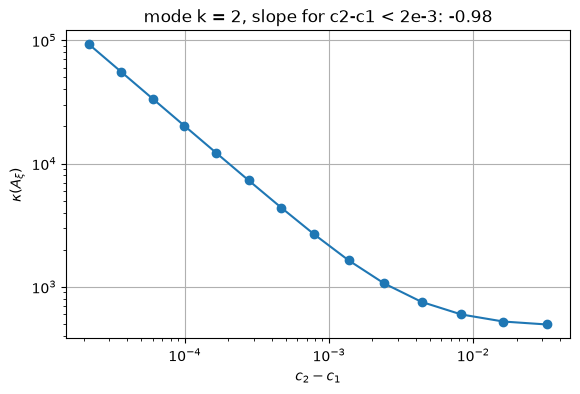

In [11]:
kk = 2
amps = 0.10 + np.geomspace(5e-4, 0.35, 14)
dcs, conds = [], []
tt = t[:60]
Ea = evolve_exact(w1, tt)
for a in amps:
    w = make_wave(a)
    Eb = evolve_exact(w, tt)
    A = np.vstack([ -1j*cam.k[kk]*np.stack([spectra(u)[0][:, kk], spectra(u)[1][:, kk]], axis=1) for u in (Ea, Eb)])
    A = A / np.linalg.norm(A, axis=0, keepdims=True)
    s = np.linalg.svd(A, compute_uv=False)
    dcs.append(w.c - w1.c); conds.append(s[0]/s[1])

dcs, conds = np.array(dcs), np.array(conds)
small = dcs < 2e-3                      # asymptotic regime: nearly equal speeds
slope = np.polyfit(np.log(dcs[small]), np.log(conds[small]), 1)[0]
fig, ax = plt.subplots()
ax.loglog(dcs, conds, "o-")
ax.set_xlabel(r"$c_2-c_1$"); ax.set_ylabel(r"$\kappa(A_\xi)$")
ax.set_title(f"mode k = {kk}, slope for c2-c1 < 2e-3: {slope:.2f}")
plt.show()